# 04 · Resultados da grade completa

5 sementes × 4 magnificações × 3 protocolos × 3 k × 1.000 episódios × 2 backbones (360.000 linhas).

### O que é vazamento aqui

Cada paciente do BreakHis tem dezenas de imagens da mesma lâmina, muito parecidas entre si. Se
imagens do **mesmo paciente** aparecem no treino e na avaliação, o modelo pode acertar por
reconhecer o paciente (cor, coloração, textura da lâmina), e não o subtipo do tumor. A nota fica
otimista. É o mesmo problema de usar `KFold` em vez de `GroupKFold` com grupos = pacientes.

| Fonte | Onde | Exemplo |
|---|---|---|
| **V1** | Dentro do episódio: support × query | A imagem 001 do paciente X está no support e a 002 está no query: a cabeça linear é treinada e testada no mesmo paciente |
| **V2** | Entre etapas: meta-treino × meta-teste | O backbone foi meta-treinado com imagens do paciente X, e o paciente X reaparece nos episódios do meta-teste |

Os três protocolos ligam ou desligam cada fonte:

| Protocolo | V2 (entre etapas) | V1 (no episódio) | Papel |
|---|---|---|---|
| **P-IMG** | sim (divisão por imagem) | sim (sorteio por imagem) | Como o artigo base faz |
| **P-MIX** | não (divisão por paciente) | sim (sorteio por imagem) | Só V1 |
| **P-PAC** | não | não (support e query com pacientes diferentes) | Cenário realista, sem vazamento |

- **Vazamento total:** Δ_total = HM(P-IMG) − HM(P-PAC), também em % do P-PAC.
- **Exposição medida em cada episódio:** `frac_V1` (% do query cujo paciente está no support) e
  `frac_V2` (% do query cujo paciente esteve no meta-treino).
- O backbone **só ImageNet** nunca viu paciente nenhum: com ele não existe V2, só V1.
- Separar V1 e V2 por subtração (P-IMG − P-MIX) **não funciona** aqui, porque o P-MIX tem mais V1
  que o P-IMG (seção 4); a decomposição está em aberto (P7 do PROJETO.md).

**Como os números são agregados:** cada rodada (semente, magnificação) dá a média de 1.000
episódios; as tabelas mostram a **média das 5 sementes ± desvio padrão entre sementes** (P6).
O desvio entre sementes é a incerteza que importa aqui: muda quais pacientes caem em cada etapa.

- **Backbones:** `meta` = meta-treinado (best_model.pt da divisão); `imagenet` = só ImageNet, sem meta-treino (sem V2).
- **Protocolos:** P-IMG (vazamento V1 + V2), P-MIX (só V1), P-PAC (sem vazamento).
- **Métricas:** HM (média harmônica de AUC seen e AUC unseen), AUCs, `acc_img`, `acc_bal_pac`, `frac_V1`, `frac_V2` (seção 8 do PROJETO.md).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["figure.dpi"] = 72
%config InlineBackend.figure_formats = ["jpeg"]
pd.set_option("display.float_format", "{:.1f}".format)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT / "results"

PROTOCOLOS = ["P-IMG", "P-MIX", "P-PAC"]
SUBTIPOS = ["DC", "F", "MC", "TA", "PT", "PC"]  # seen (DC, F, MC, TA) e unseen do mtst (PT, PC)

df = pd.concat(pd.read_csv(f) for f in sorted((RESULTS / "mtst").glob("*_seed*[0-9].csv")))
treinos = pd.DataFrame(json.loads(p.read_text()) for p in (RESULTS / "train").glob("*/config.json"))
df.shape

(360000, 21)

## 1. Visão geral

In [2]:
assert df.groupby(["magnificacao", "semente", "backbone", "protocolo", "k_shot"]).size().eq(1000).all()
df.groupby(["magnificacao", "semente"]).size().unstack()  # 18.000 linhas por rodada

semente,0,10,42,109,2026
magnificacao,,,,,
40,18000,18000,18000,18000,18000
100,18000,18000,18000,18000,18000
200,18000,18000,18000,18000,18000
400,18000,18000,18000,18000,18000


## 2. HM no meta-teste

Função de apoio: média por rodada (1.000 episódios) e depois média ± desvio entre as 5 sementes.

In [3]:
def por_rodada(d, metrica):
    """Média de cada rodada: uma linha por (backbone, protocolo, magnificação, k, semente)."""
    return d.groupby(["backbone", "protocolo", "magnificacao", "k_shot", "semente"])[metrica].mean()


def media_dp(d, metrica, backbone):
    """Tabela magnificação × k (linhas) por protocolo (colunas), com 'média ± dp' entre sementes."""
    r = por_rodada(d[d.backbone == backbone], metrica).groupby(["protocolo", "magnificacao", "k_shot"]).agg(["mean", "std"])
    texto = r["mean"].map("{:.1f}".format) + " ± " + r["std"].map("{:.1f}".format)
    return texto.unstack("protocolo")[PROTOCOLOS]

### 2.1 HM do Backbone meta-treinado

In [4]:
media_dp(df, "hm", "meta")

protocolo                 P-IMG       P-MIX        P-PAC
magnificacao k_shot                                     
40           1       81.6 ± 1.2  75.9 ± 3.4   57.5 ± 6.2
             5       92.3 ± 1.4  91.0 ± 1.7   59.5 ± 6.7
             10      95.4 ± 0.9  95.4 ± 1.1   59.8 ± 6.9
100          1       82.0 ± 2.1  72.8 ± 2.4   55.1 ± 1.1
             5       92.3 ± 1.5  88.8 ± 1.8   56.7 ± 0.6
             10      94.9 ± 1.1  94.3 ± 1.2   56.4 ± 1.3
200          1       80.1 ± 1.0  71.7 ± 3.2   52.0 ± 7.2
             5       91.1 ± 0.7  89.2 ± 1.9   53.6 ± 8.9
             10      94.4 ± 0.7  94.8 ± 1.1   53.9 ± 9.3
400          1       79.6 ± 2.0  72.2 ± 5.9   55.7 ± 9.0
             5       90.4 ± 1.3  87.8 ± 3.2  56.3 ± 10.4
             10      93.6 ± 0.8  93.1 ± 1.8  56.8 ± 10.4

### 2.2 HM do Backbone só ImageNet (sem meta-treino, sem V2)

In [5]:
media_dp(df, "hm", "imagenet")

protocolo                 P-IMG       P-MIX       P-PAC
magnificacao k_shot                                    
40           1       68.8 ± 0.5  76.4 ± 3.5  58.0 ± 6.3
             5       84.7 ± 0.2  91.2 ± 1.8  60.1 ± 6.8
             10      90.0 ± 0.3  95.3 ± 1.1  60.6 ± 7.0
100          1       64.2 ± 0.4  72.0 ± 1.8  53.3 ± 3.5
             5       80.1 ± 0.6  88.0 ± 1.2  54.2 ± 4.6
             10      87.1 ± 0.5  93.8 ± 0.9  54.3 ± 4.9
200          1       62.4 ± 0.9  70.8 ± 2.2  52.4 ± 5.6
             5       78.5 ± 0.8  88.8 ± 0.8  54.0 ± 6.3
             10      86.1 ± 0.9  94.6 ± 0.6  54.6 ± 6.5
400          1       61.1 ± 0.9  67.7 ± 1.3  48.3 ± 2.8
             5       76.3 ± 1.0  86.3 ± 1.3  48.4 ± 3.8
             10      83.4 ± 0.9  92.4 ± 1.2  49.2 ± 4.7

### 2.3 Diferença entre HM por protocolo: Δ_total = P-IMG − P-PAC
Δ = HM_P_IMG - HM_P_PAC.  
Calculado em cada semente e depois resumido (média ± dp). Δ% = Δ / P-PAC × 100.

In [6]:
def delta(d, a="P-IMG", b="P-PAC"):
    r = por_rodada(d, "hm").unstack("protocolo")
    out = pd.DataFrame({"delta": r[a] - r[b], "delta_pct": (r[a] - r[b]) / r[b] * 100})
    s = out.groupby(["backbone", "magnificacao", "k_shot"]).agg(["mean", "std"])
    return pd.DataFrame({
        "Δ (pontos)": s[("delta", "mean")].map("{:.1f}".format) + " ± " + s[("delta", "std")].map("{:.1f}".format),
        "Δ%": s[("delta_pct", "mean")].map("{:.0f}%".format),
    }).unstack("backbone")


delta(df)

Δ (pontos)                    Δ%     
backbone               imagenet         meta imagenet meta
magnificacao k_shot                                       
40           1       10.9 ± 6.0   24.1 ± 6.9      20%  43%
             5       24.6 ± 6.9   32.8 ± 7.3      42%  57%
             10      29.4 ± 7.1   35.5 ± 7.2      50%  61%
100          1       10.9 ± 3.3   26.9 ± 1.8      21%  49%
             5       25.9 ± 4.2   35.5 ± 1.5      49%  63%
             10      32.8 ± 4.4   38.5 ± 1.2      61%  68%
200          1       10.0 ± 5.0   28.1 ± 7.2      20%  56%
             5       24.5 ± 6.1   37.5 ± 9.0      47%  74%
             10      31.5 ± 6.3   40.6 ± 9.2      59%  80%
400          1       12.8 ± 2.6   24.0 ± 7.5      27%  45%
             5       27.9 ± 3.5   34.2 ± 9.9      58%  64%
             10      34.2 ± 4.5  36.7 ± 10.2      71%  68%

Resumo por k (todas as magnificações e sementes juntas):

In [7]:
r = por_rodada(df, "hm").unstack("protocolo")
(r["P-IMG"] - r["P-PAC"]).groupby(["backbone", "k_shot"]).agg(["mean", "std", "min", "max"]).unstack("backbone")

mean           std           min           max     
backbone imagenet meta imagenet meta imagenet meta imagenet meta
k_shot                                                          
1            11.2 25.8      4.2  6.1      2.5 11.6     18.3 35.9
5            25.7 35.0      5.1  7.2     15.2 18.0     34.0 47.5
10           32.0 37.8      5.5  7.4     20.3 20.1     41.9 51.6

### 2.4 Gráfico: HM × k

Um painel por magnificação; linha cheia = meta-treinado, tracejada = só ImageNet. Barras = dp entre sementes.

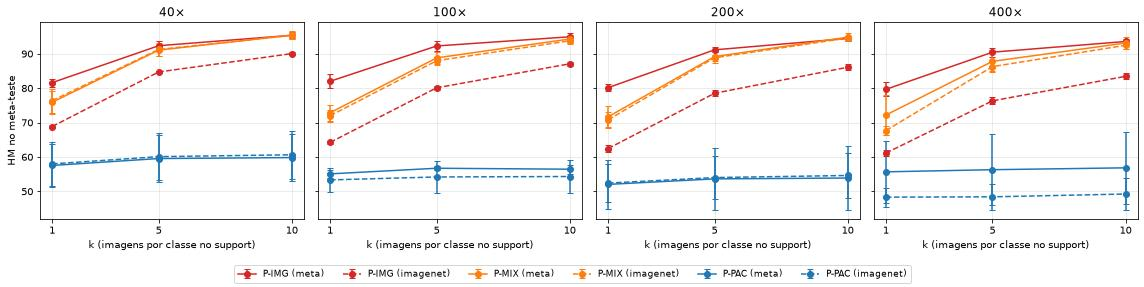

In [8]:
r = por_rodada(df, "hm").groupby(["backbone", "protocolo", "magnificacao", "k_shot"]).agg(["mean", "std"])
cores = dict(zip(PROTOCOLOS, ["tab:red", "tab:orange", "tab:blue"]))
fig, axs = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, mag in zip(axs, sorted(df.magnificacao.unique())):
    for protocolo in PROTOCOLOS:
        for backbone, estilo in [("meta", "-"), ("imagenet", "--")]:
            s = r.loc[(backbone, protocolo, mag)]
            ax.errorbar(s.index, s["mean"], yerr=s["std"], ls=estilo, marker="o", capsize=3, color=cores[protocolo],
                        label=f"{protocolo} ({backbone})")
    ax.set(title=f"{mag}×", xlabel="k (imagens por classe no support)", xticks=[1, 5, 10])
    ax.grid(alpha=0.3)
axs[0].set_ylabel("HM no meta-teste")
fig.legend(*axs[0].get_legend_handles_labels(), loc="lower center", ncol=6, fontsize=9)
plt.tight_layout(rect=(0, 0.08, 1, 1))

## 3. Outras métricas

Média de todas as magnificações e sementes (média das 20 rodadas ± dp entre rodadas).

In [9]:
METRICAS = ["auc_seen", "auc_unseen", "hm", "acc_img", "acc_bal_pac"]
r = df.groupby(["backbone", "protocolo", "k_shot", "magnificacao", "semente"])[METRICAS].mean()
r.groupby(["backbone", "protocolo", "k_shot"]).mean()

auc_seen  auc_unseen   hm  acc_img  acc_bal_pac
backbone protocolo k_shot                                                 
imagenet P-IMG     1           65.3        65.1 64.2     46.7         46.4
                   5           80.5        80.4 79.9     64.5         63.8
                   10          86.7        87.3 86.6     72.9         72.3
         P-MIX     1           75.2        70.3 71.7     55.7         54.7
                   5           91.3        86.7 88.6     77.2         76.0
                   10          95.8        92.6 94.0     85.3         84.5
         P-PAC     1           58.7        53.3 53.0     39.7         39.4
                   5           60.5        54.3 54.2     41.5         41.0
                   10          61.0        54.9 54.7     42.1         41.5
meta     P-IMG     1           88.9        75.7 80.8     68.6         67.7
                   5           95.3        88.5 91.5     81.7         80.8
                   10          96.7        92.7 94.6     85.6         85.0
         P-MIX     1           76.9        71.7 73.1     57.5         56.4
                   5           91.7        87.4 89.2     78.0         76.7
                   10          96.0        93.1 94.4     85.8         84.9
         P-PAC     1           61.7        55.3 55.1     42.3         41.5
                   5           63.0        56.7 56.5     43.7         42.6
                   10          63.0        57.0 56.7     43.9         42.8

## 4. Exposição ao vazamento

`frac_V1`: % do query cujo paciente está no support. `frac_V2`: % do query cujo paciente
esteve no meta-treino (só existe no backbone meta). No P-PAC as duas precisam ser zero.

In [10]:
assert (df.loc[df.protocolo == "P-PAC", ["frac_V1", "frac_V2"]] == 0).all().all()
assert (df.loc[df.protocolo == "P-MIX", "frac_V2"] == 0).all()
df[df.backbone == "meta"].groupby(["protocolo", "k_shot"])[["frac_V1", "frac_V2"]].mean().mul(100).unstack("k_shot")

frac_V1           frac_V2          
k_shot         1    5    10      1    5    10
protocolo                                    
P-IMG        20.8 59.4 76.1    66.7 66.7 66.7
P-MIX        39.7 82.4 93.0     0.0  0.0  0.0
P-PAC         0.0  0.0  0.0     0.0  0.0  0.0

HM por faixa de `frac_V1` (P-IMG e P-MIX, todos os k e magnificações): quanto mais do query
compartilha paciente com o support, maior a HM?

In [11]:
d = df[df.protocolo.isin(["P-IMG", "P-MIX"])].copy()
d["faixa_V1"] = pd.cut(d.frac_V1, [-0.01, 0, 0.25, 0.5, 0.75, 1], labels=["0", "0–25%", "25–50%", "50–75%", "75–100%"])
t = d.groupby(["backbone", "faixa_V1"], observed=True).hm.agg(["mean", "count"]).unstack("backbone")
t

mean         count       
backbone imagenet meta imagenet   meta
faixa_V1                              
0            56.1 70.2      150    150
0–25%        62.5 76.8    16157  16157
25–50%       71.8 79.6    26618  26618
50–75%       82.6 89.9    29475  29475
75–100%      91.0 93.6    47600  47600

In [12]:
# referência: o P-PAC (frac_V1 = 0 por construção)
df[df.protocolo == "P-PAC"].groupby("backbone").hm.mean()

backbone
imagenet   53.9
meta       56.1
Name: hm, dtype: float64

## 5. Máximos e mínimos

### 5.1 Por rodada: melhor e pior (semente, magnificação) de cada protocolo

In [13]:
r = por_rodada(df, "hm").reset_index()
def extremos(g):
    mn, mx = g.loc[g.hm.idxmin()], g.loc[g.hm.idxmax()]
    return pd.Series({"min": mn.hm, "min_em": f"{int(mn.magnificacao)}× s{int(mn.semente)}",
                      "max": mx.hm, "max_em": f"{int(mx.magnificacao)}× s{int(mx.semente)}", "amplitude": mx.hm - mn.hm})
r.groupby(["backbone", "protocolo", "k_shot"]).apply(extremos, include_groups=False)

min      min_em  max      max_em  amplitude
backbone protocolo k_shot                                             
imagenet P-IMG     1      60.4     400× s0 69.5     40× s10        9.2
                   5      75.2     400× s0 85.0     40× s10        9.8
                   10     82.2     400× s0 90.4      40× s0        8.2
         P-MIX     1      66.2  400× s2026 80.6   40× s2026       14.4
                   5      84.8  400× s2026 92.9   40× s2026        8.1
                   10     90.9  400× s2026 96.4   40× s2026        5.5
         P-PAC     1      43.8   400× s109 66.4   40× s2026       22.6
                   5      42.1   400× s109 69.2   40× s2026       27.1
                   10     41.7   400× s109 69.2   40× s2026       27.5
meta     P-IMG     1      77.3    400× s10 84.6  100× s2026        7.3
                   5      89.0    400× s10 94.2  100× s2026        5.3
                   10     92.6    400× s10 96.5     40× s10        3.8
         P-MIX     1      66.2  400× s2026 81.7    400× s42       15.5
                   5      84.8  400× s2026 92.9   40× s2026        8.1
                   10     90.9  400× s2026 96.4   40× s2026        5.5
         P-PAC     1      43.1   200× s109 71.2    400× s42       28.1
                   5      42.8   200× s109 74.0    400× s42       31.2
                   10     42.1   200× s109 74.2    400× s42       32.2

### 5.2 Por episódio: variação da HM

Desvio padrão da HM entre episódios e % de episódios com HM abaixo de 50 (todas as rodadas juntas).

In [14]:
q = df.groupby(["backbone", "k_shot", "protocolo"]).hm
pd.concat({"dp": q.std(), "% HM < 50": q.apply(lambda h: (h < 50).mean() * 100)}, axis=1).unstack("protocolo")

dp             % HM < 50            
protocolo       P-IMG P-MIX P-PAC     P-IMG P-MIX P-PAC
backbone k_shot                                        
imagenet 1       11.3  12.2  17.2      11.0   4.6  43.2
         5        9.2   7.9  17.9       0.3   0.1  41.1
         10       7.3   5.3  17.9       0.0   0.0  40.0
meta     1       12.8  13.2  19.3       2.3   5.2  38.7
         5        6.9   8.0  19.5       0.0   0.1  36.5
         10       4.9   5.3  19.7       0.0   0.0  35.9

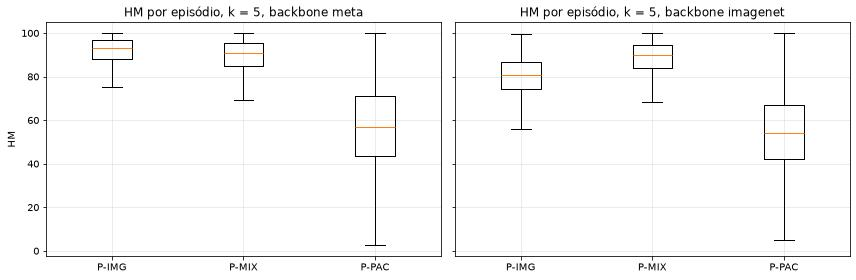

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, backbone in zip(axs, ["meta", "imagenet"]):
    d = df[(df.backbone == backbone) & (df.k_shot == 5)]
    ax.boxplot([d.hm[d.protocolo == p] for p in PROTOCOLOS], tick_labels=PROTOCOLOS, showfliers=False)
    ax.set(title=f"HM por episódio, k = 5, backbone {backbone}")
    ax.grid(alpha=0.3)
axs[0].set_ylabel("HM")
plt.tight_layout()

## 6. AUC por classe

Média sobre os episódios em que a classe aparece (k = 5, todas as magnificações e sementes).
AUC abaixo de 50 indica que a cabeça ordena **ao contrário**: sinal de atalho (ex.: pela lâmina).

In [16]:
d = df[df.k_shot == 5]
d.groupby(["backbone", "protocolo"])[[f"auc_{c}" for c in SUBTIPOS]].mean()

auc_DC  auc_F  auc_MC  auc_TA  auc_PT  auc_PC
backbone protocolo                                               
imagenet P-IMG        80.3   81.2    77.9    84.9    84.9    75.9
         P-MIX        88.5   94.0    89.3    94.8    90.0    83.3
         P-PAC        69.2   72.7    42.5    60.4    54.2    54.5
meta     P-IMG        94.9   93.5    95.1    98.2    90.5    86.4
         P-MIX        89.3   94.2    89.3    95.2    90.9    83.8
         P-PAC        71.8   73.0    47.5    63.0    58.6    54.7

In [17]:
# por semente, no P-PAC: classes com 2 pacientes no mtst dependem de quais pacientes caíram
d[(d.protocolo == "P-PAC") & (d.backbone == "meta")].groupby("semente")[[f"auc_{c}" for c in SUBTIPOS]].mean()

,auc_DC,auc_F,auc_MC,auc_TA,auc_PT,auc_PC
semente,,,,,,
0,65.7,93.6,52.9,39.6,55.6,52.0
10,68.2,91.0,72.1,43.8,63.8,51.9
42,76.6,75.6,43.9,87.1,57.5,61.7
109,77.7,41.4,33.2,64.8,60.0,51.5
2026,70.9,63.3,36.2,79.4,56.5,56.3


## 7. Efeito do meta-treino: meta − ImageNet

Diferença da HM entre os dois backbones no mesmo protocolo e nos mesmos episódios, calculada em
cada rodada (semente × magnificação). Média ± desvio padrão entre as 20 rodadas.

In [18]:
r = por_rodada(df, "hm").unstack("backbone")
d = (r["meta"] - r["imagenet"]).groupby(["protocolo", "k_shot"]).agg(["mean", "std"])
(d["mean"].map("{:+.1f}".format) + " ± " + d["std"].map("{:.1f}".format)).unstack("protocolo")[PROTOCOLOS]

protocolo,P-IMG,P-MIX,P-PAC
k_shot,,,
1,+16.7 ± 2.7,+1.4 ± 3.4,+2.1 ± 5.2
5,+11.6 ± 2.6,+0.6 ± 1.7,+2.4 ± 5.8
10,+7.9 ± 1.9,+0.4 ± 0.8,+2.0 ± 5.5


## 8. Resultados no meta-treino

In [19]:
treinos.pivot_table(index=["divisao", "seed"], columns="mag", values="melhor_hm")

mag           40   100  200  400
divisao seed                    
img     0    95.1 93.7 93.2 92.9
        10   93.4 92.3 93.2 91.2
        42   96.0 92.6 93.8 93.0
        109  93.4 93.8 92.9 92.1
        2026 92.8 94.6 94.6 93.5
pac     0    58.9 63.0 55.6 59.7
        10   57.7 52.1 61.7 59.2
        42   66.2 63.5 60.9 64.1
        109  55.9 54.3 56.4 73.6
        2026 49.0 46.7 47.0 56.7

In [20]:
treinos.groupby("divisao").agg(
    melhor_epoca_mediana=("melhor_epoca", "median"),
    treinos_na_epoca_0_ou_1=("melhor_epoca", lambda e: (e <= 1).sum()),
    epocas_rodadas_media=("epocas_rodadas", "mean"),
    hm_mval_media=("melhor_hm", "mean"),
)

,melhor_epoca_mediana,treinos_na_epoca_0_ou_1,epocas_rodadas_media,hm_mval_media
divisao,,,,
img,36.5,0,46.3,93.4
pac,1.0,12,17.9,58.1


## Resumo

Números do backbone meta-treinado, salvo indicação; "a confirmar" = leitura, não teste formal.

1. **Vazamento total grande e consistente.** Δ_total = P-IMG − P-PAC de 24 a 28 pontos de HM
   com k = 1, de 33 a 38 com k = 5 e de 36 a 41 com k = 10, conforme a magnificação (seção 2.3):
   **+43% a +80%** sobre o P-PAC. Positivo em todas as 20 rodadas, em todo k (seção 2.3).
2. **No P-PAC a HM não sobe com k** (52 a 60 em todas as combinações); no P-IMG sobe de ~80 para
   ~95. O ganho com mais exemplos por classe vem quase todo do vazamento: o `frac_V1` do P-IMG
   cresce de 20% (k = 1) para 80% (k = 10) (seção 4).
3. **O V1 sozinho já explica a maior parte.** O P-MIX (sem V2) fica de 16 a 41 pontos acima do
   P-PAC e encosta no P-IMG com k = 10; com o backbone só ImageNet, o P-MIX passa o P-IMG. A HM
   cresce com a fração do query que compartilha paciente com o support: de 77 (até 25%) a 94
   (75–100%) (seção 4).
4. **O meta-treino ajuda muito só com V2:** meta − ImageNet = +8 a +17 no P-IMG, +0,4 a +1,4 no
   P-MIX e +2,0 a +2,4 no P-PAC, onde o desvio entre rodadas (~5) é maior que o efeito (seção 7). Na divisão por paciente, 12 dos 20 treinos escolhem a
   época 0 ou 1, isto é, o backbone fica praticamente igual ao do ImageNet (seção 8).
5. **O resultado sem vazamento depende muito dos pacientes sorteados.** No P-PAC, o dp entre
   sementes chega a 10 pontos (400×), a média por rodada vai de 42 a 74 (seção 5.1), e 36% a 43%
   dos episódios ficam com HM abaixo de 50 (seção 5.2). Com vazamento, o resultado é estável
   (dp entre sementes de 0,7 a 2,1 pontos no P-IMG).
6. **Classes com poucos pacientes podem ficar abaixo de 50 de AUC** no P-PAC: MC na média (42 a 48),
   e TA, F ou MC em sementes específicas (seção 6). Sinal de que a cabeça aprende traços do paciente
   (ou da lâmina) do support, e não do subtipo; a confirmar.
7. **Unidade de contagem:** `acc_img` e `acc_bal_pac` diferem em ~1 ponto; aqui, contar por imagem
   ou por paciente quase não muda a acurácia (seção 3).